# **Mapping short-let pressure in Bristol: A neighbourhood analysis of Airbnb listings**


# ML objectives

**Question.** Can a listing's own characteristics predict whether it belongs to a professional operator (a host with 3 or more listings), and which characteristics separate the two groups?

**Why machine learning, after the hypothesis tests.** 

H1 to H3 compare one measure at a time. Machine learning asks a different question: when several characteristics are considered together, which ones carry the most information about host type? The aim is **interpretation, not prediction for its own sake**. A council gains little from a model that flags operators accurately but cannot say why. This shapes every choice below.

**Target and inputs.**
- Target: `is_operator` (3+ listings), on active listings.
- Candidate inputs: property size (`accommodates`), entire home, availability, rating, review count, superhost status and price.
- The host-count columns are excluded because they define the target, and a model that reads them has simply been handed the answer.
- `beds` and `bedrooms` are excluded because they overlap heavily with `accommodates` (V8). `minimum_nights` is excluded because H2 found no meaningful, robust difference.
- Neighbourhood is left out on purpose. H1 already analyses geography, and 34 area categories with few listings each would let the model lean on location and shrink what it can say about listing characteristics. [CONFIRM: this is your reason. Edit it if not.]

**Methods considered.**

| Method | Considered for | Decision |
|---|---|---|
| Logistic regression | Interpretable: coefficients and odds ratios give direction and size of each effect | **Used** |
| Decision tree | Interpretable: readable rules, handles non-linear patterns such as the U-shaped availability (V4), needs no scaling | **Used** |
| Random forest, gradient boosting | Often more accurate | Not used: harder to interpret, and the aim is explanation, not accuracy |
| k-nearest neighbours, neural networks | Flexible | Not used: no readable model to explain, and unnecessary at this data size |
| Naive Bayes | Simple, fast | Not used: assumes independent inputs, but V8 shows the size variables overlap |
| Clustering | Finds groups without labels | Not used: the labels are known, so a supervised method answers the question directly |

**Why these two models.** 

I compare a decision tree with a logistic regression for complementary reasons. The tree shows the rules, and can capture patterns a straight-line model cannot. The logistic regression shows the direction and strength of each input as a single number. If two quite different model families point to the same characteristics, that is stronger evidence than either alone. I did not decide in advance which would be better, so the comparison is part of the method.

**Methodological safeguards (research design choices).**

- **Split by host.** Listings from one host resemble each other, so a random split would let the model recognise hosts it had already seen and inflate the test score. No host appears in both training and test sets.
- **Host-grouped cross-validation** on the training data, so settings are chosen without touching the test set. The test set is used once.
- **Pipelines.** Missing-value filling and scaling are learned from training data only, so nothing leaks from held-out data.
- **A baseline.** A classifier that always predicts "casual". A model must beat it to show it learned anything.
- **F1 for the operator class, not accuracy alone.** Operator listings are the group of interest, and accuracy can hide a model that ignores them.
- **Robustness checks.** Price is removed to test whether it adds anything, and the largest host is removed from training to test how much one host shapes the result.

**Success criteria.** A model is useful here if it beats the baseline on host-grouped data, and if the characteristics it relies on are stable across the checks above. Differences between models smaller than the fold-to-fold spread are not treated as meaningful.

**What this stage cannot do.** It does not show causes, and it does not measure housing pressure. Coefficients and importances describe what these fitted models used, not why operators behave differently.

**Sources.** 

scikit-learn user guide: [logistic regression](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression), [decision trees](https://scikit-learn.org/stable/modules/tree.html), [ensemble methods](https://scikit-learn.org/stable/modules/ensemble.html).

# Change working directory

In [ ]:
import os
current_dir = os.getcwd()
current_dir

In [2]:
os.chdir(os.path.dirname(current_dir))
print("You set a new current directory")

You set a new current directory


In [ ]:
current_dir = os.getcwd()
current_dir

# Import transformed data

In [4]:
from pathlib import Path  
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV, GroupKFold, cross_validate
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)


RANDOM_STATE = 42


In [5]:
df = pd.read_csv("data/processed/listings_clean.csv", dtype={"id": str},
                 parse_dates=["first_review", "last_review"])
active = df[df["is_active"]].copy()
print(df.shape, active.shape) 

(2932, 51) (2561, 51)


# 1. Split the data

**Target:** 

`is_operator` (host with 3+ listings), on active listings.

**Features:** 

- `accommodates`, `price`, `is_entire_home`, `availability_365`, `review_scores_rating`, `number_of_reviews`, `host_is_superhost`. 
- Host-count columns are excluded because they define the target. 
- `beds` and `bedrooms` are dropped because they correlate 0.85-0.90 with `accommodates` (V8). - `minimum_nights` is dropped because H2 found a negligible effect that was not robust to removing the largest host. 


**Split:** 

80/20, grouped by host so that no host appears in both sets. Otherwise listings from the same host would leak patterns between training and testing and inflate the test score. The test set is used once, at the end.

**Baseline:** 
A classifier that always predicts the larger group ("casual"). Both models must beat it to show they learned anything.

**Missing values:** 

These are left as they are here as imputation and scaling happen inside the pipeline. Fitted on training data only.

In [6]:

target = "is_operator"
features = ["accommodates", "price", "is_entire_home", "availability_365",
            "review_scores_rating", "number_of_reviews", "host_is_superhost"]

X = active[features].astype(float)
y = active[target].astype(int)
groups = active["host_key"]

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups=groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print(X_train.shape, X_test.shape)
print("Operator share  train:", round(y_train.mean(), 3), " test:", round(y_test.mean(), 3))
print("Hosts in both sets:", len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])))   # expect 0
print(X_train.isna().sum())

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("Baseline accuracy on test:", round(baseline.score(X_test, y_test), 3))

(1971, 7) (590, 7)
Operator share  train: 0.397  test: 0.495
Hosts in both sets: 0
accommodates              0
price                   240
is_entire_home            0
availability_365          0
review_scores_rating    179
number_of_reviews         0
host_is_superhost         0
dtype: int64
Baseline accuracy on test: 0.505


In [7]:
top_host = active["host_key"].value_counts().index[0]
print("Largest host in test set:", top_host in set(groups.iloc[test_idx]))
print("Their listings in test:", (groups.iloc[test_idx] == top_host).sum(), "of", len(test_idx))

Largest host in test set: False
Their listings in test: 0 of 590


In [8]:
test_hosts = groups.iloc[test_idx]
print("Hosts in test set:", test_hosts.nunique())
print(test_hosts.value_counts().head(5))

Hosts in test set: 295
host_key
285    65
564    33
534    25
670    21
787    19
Name: count, dtype: int64


**Result:** 

The split gives 1,971 training and 590 test listings (23% in test; a group split cannot hit exactly 20%). No host appears in both sets.

**Class balance:** 

The operator share is 39.7% in training and 49.5% in testing, against 42% across all active listings. This difference comes from the host-grouped split because operators come in blocks. This means that which hosts land in the test set moves the share. I did not change the random seed to even it out. The largest host (127 listings) is in the training set, so it does not affect the test score.

**Baseline:** 

A classifier that always predicts "casual" scores 50.5% accuracy on the test set (about 58% across all active listings). This is the bar both models must beat. It is a low bar because the test set is close to balanced, so model comparisons also use cross-validation on the training data and per-group precision and recall, not accuracy alone.

**Missing values (training set):** 

`price` is missing for 240 listings (12%) and `review_scores_rating` for 179 (9%). They are imputed inside the pipeline, fitted on training data only, with an indicator for missingness, because a missing price or rating may itself carry information.

**Limitations:** 

The test set has 590 listings but far fewer independent hosts, so the test score is uncertain and a difference of a few points between models is not meaningful. 

The test set contains 295 hosts, but the five largest hold 28% of its listings (the largest has 65), and they provide over half of its operator listings. So the operator side of the test score depends heavily on a handful of hosts. Because the largest host is in the training data, a robustness check refits the models without it.

# 2. Building the pipeline


**Models:** 

- Logistic regression (an interpretable linear model)
- Decision tree (which can capture non-linear patterns and interactions) 
- Compared with a baseline that always predicts "casual".

**Preprocessing:** 
- Missing `price` and `review_scores_rating` values are filled with the median, with a missing-value indicator added.
-  `price` and `number_of_reviews` are log-transformed (both are strongly skewed) and all numeric inputs are scaled. The tree needs neither. 
- All preprocessing sits inside a pipeline, so it is fitted on training data only and no information leaks from held-out data.

**Evaluation:** 
- 5-fold cross-validation on the training set, grouped by host so that no host appears in both a training and a validation fold. 
- Accuracy, precision, recall and F1 for the operator class are reported as mean ± standard deviation across folds. The test set is not used until the final model is chosen.



#### 1: Define the input groups

Inputs are grouped by how they need to be treated. `price` and `number_of_reviews` are strongly skewed (V0), so they are log-transformed for the logistic regression. The other numeric inputs are only scaled. The two yes/no inputs are already 0/1 so do not need to be changed.

In [9]:
log_cols = ["price", "number_of_reviews"]                                
num_cols = ["accommodates", "availability_365", "review_scores_rating"]
bin_cols = ["is_entire_home", "host_is_superhost"]

#### Step 2: Preprocessing for the logistic regression

Logistic regression is sensitive to the size and skew of its inputs, so each numeric column is (in order): log-transformed if skewed, missing values filled with the median, then scaled to mean 0 and standard deviation 1. `add_indicator=True` adds a 0/1 column for any input that had gaps (price and rating), because a missing value may itself carry information. Everything sits inside a pipeline, so medians and scaling are learned from training data only.

In [10]:
lr_prep = ColumnTransformer([
    ("log", Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                      ("imp", SimpleImputer(strategy="median", add_indicator=True)),
                      ("scale", StandardScaler())]), log_cols),
    ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                      ("scale", StandardScaler())]), num_cols),
    ("bin", "passthrough", bin_cols),
], verbose_feature_names_out=False)

#### Step 3: Preprocessing for the decision tree

A decision tree splits on the order of values, so scaling and log transforms make no difference and are skipped. It only needs the gaps filled; the same median fill and missing-value indicator are used for the two columns with gaps, and every other column is passed through.

In [11]:
tree_prep = ColumnTransformer(
    [("imp", SimpleImputer(strategy="median", add_indicator=True), ["price", "review_scores_rating"])],
    remainder="passthrough", verbose_feature_names_out=False)

#### Step 4: Check the preprocessing

Before modelling, we need to confirm that the preprocessing does what is intended. In particular, we want to see that no missing values remain, and the missing-value indicator columns have been added. This fit is just an inspection so only uses the training set only.

In [12]:
X_lr = lr_prep.fit_transform(X_train)
print("Logistic inputs:", X_lr.shape, "| missing values left:", int(np.isnan(X_lr).sum()))
print(list(lr_prep.get_feature_names_out()))

X_tree = tree_prep.fit_transform(X_train)
print("Tree inputs:", X_tree.shape, "| missing values left:", int(np.isnan(X_tree).sum()))

Logistic inputs: (1971, 9) | missing values left: 0
['price', 'number_of_reviews', 'missingindicator_price', 'accommodates', 'availability_365', 'review_scores_rating', 'missingindicator_review_scores_rating', 'is_entire_home', 'host_is_superhost']
Tree inputs: (1971, 9) | missing values left: 0


#### Step 5: Assemble the models

Each model is bundled with its preprocessing into one pipeline. A baseline that always predicts "casual" is included so that the real models have something to beat. 

The decision tree starts at depth 4 (shallow enough to read). We will tune its depth and the regularisation strength of the logistic regression in a later step.

In [13]:
models = {
    "Baseline (always casual)": Pipeline([("model", DummyClassifier(strategy="most_frequent"))]),
    "Logistic regression": Pipeline([("prep", lr_prep),
                                     ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
    "Decision tree (depth 4)": Pipeline([("prep", tree_prep),
                                         ("model", DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE))]),
}

#### Step 6: Set up grouped cross-validation

The models are compared with 5-fold cross-validation on the training set only. Folds are grouped by host, so no host appears in both a training and a validation fold, matching the train/test split. 

The pipelines are refitted inside each fold, so preprocessing never sees the validation data. Accuracy, precision, recall and F1 are reported for the operator class.

In [14]:
groups_train = groups.iloc[train_idx]
cv = GroupKFold(n_splits=5)
scoring = ["accuracy", "precision", "recall", "f1"]

#### Step 7: Compare the models

Mean and standard deviation across the five folds. The spread shows how much each result depends on which hosts fall in which fold; differences smaller than the spread are not meaningful.

In [15]:
rows = []
for name, pipe in models.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv, groups=groups_train, scoring=scoring)
    rows.append({"model": name,
                 **{m: f"{res['test_' + m].mean():.3f} ± {res['test_' + m].std():.3f}" for m in scoring}})
cv_results = pd.DataFrame(rows)
print(cv_results.to_string(index=False))

c:\Users\chheb\OneDrive\Documents\Programming\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\chheb\OneDrive\Documents\Programming\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\chheb\OneDrive\Documents\Programming\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capital

                   model      accuracy     precision        recall            f1
Baseline (always casual) 0.603 ± 0.006 0.000 ± 0.000 0.000 ± 0.000 0.000 ± 0.000
     Logistic regression 0.628 ± 0.030 0.558 ± 0.070 0.272 ± 0.086 0.362 ± 0.087
 Decision tree (depth 4) 0.661 ± 0.020 0.572 ± 0.020 0.561 ± 0.087 0.564 ± 0.055


**Result:** 

Both models beat the baseline of always predicting "casual" (60.3% accuracy), but by different margins.

The decision tree scores best (accuracy 0.661 ± 0.020, precision 0.572, recall 0.561, F1 0.564). 

The logistic regression is only 2.5 points above the baseline on accuracy (0.628 ± 0.030) and finds just 27% of operator listings (recall 0.272, F1 0.362).

**Interpretation:** 

The tree's advantage is clear on recall and F1 (the gap is larger than the fold-to-fold spread) but not on accuracy (3 points, within the spread). 

A possible reason for is that the tree can use non-linear patterns such as the U-shaped availability distribution (V4), which the linear model cannot. But this was not tested. The logistic regression's low recall also reflects its default decision threshold, so tuning (class weighting) may narrow the gap. Overall, listing characteristics separate operator and casual listings only modestly, consistent with the weak correlations in V8.

**Limitations:** 

Results are cross-validated on the training set only; the test set has not been used. Folds contain few large hosts, so the spread is rough and likely to understate the real uncertainty.

# 3. Tuning the models

Both models have settings that control how closely they fit the training data, which affects how well they generalise to unseen hosts.

- **Decision tree:** `max_depth` (how many questions the tree can ask) and `min_samples_leaf` (the smallest group allowed at the end of a branch). Deeper trees with tiny leaves tend to memorise the training data.
- **Logistic regression:** `C` (regularisation strength; smaller means a simpler model) and `class_weight` (whether the less common operator class is up-weighted, which tends to raise recall).

Settings are compared on F1 for the operator class, using the same host-grouped folds as before. The test set is not used.

In [16]:
tree_grid = {"model__max_depth": [2, 3, 4, 5, 6, 8],
             "model__min_samples_leaf": [5, 20, 50]}

lr_grid = {"model__C": [0.01, 0.1, 1, 10],
           "model__class_weight": [None, "balanced"]}

#### Run the search

Every combination is scored with 5-fold grouped cross-validation. We will keep the best combination by mean F1. Training scores are also recorded so we can check overfitting.

In [17]:
searches = {
    "Decision tree": GridSearchCV(models["Decision tree (depth 4)"], tree_grid, scoring="f1",
                                  cv=cv, return_train_score=True),
    "Logistic regression": GridSearchCV(models["Logistic regression"], lr_grid, scoring="f1",
                                        cv=cv, return_train_score=True),
}

for name, gs in searches.items():
    gs.fit(X_train, y_train, groups=groups_train)
    spread = gs.cv_results_["std_test_score"][gs.best_index_]
    print(f"{name}: best F1 = {gs.best_score_:.3f} ± {spread:.3f}")
    print("   ", gs.best_params_)

Decision tree: best F1 = 0.563 ± 0.053
    {'model__max_depth': 4, 'model__min_samples_leaf': 5}
Logistic regression: best F1 = 0.541 ± 0.063
    {'model__C': 0.01, 'model__class_weight': 'balanced'}


#### Check for overfitting in the tree

For the tree, training F1 and validation F1 are plotted against depth (at the best leaf size). If training F1 keeps rising while validation F1 flattens or falls, the tree is memorising the training listings and the extra depth is not helping. The depth to choose is where validation F1 stops improving.

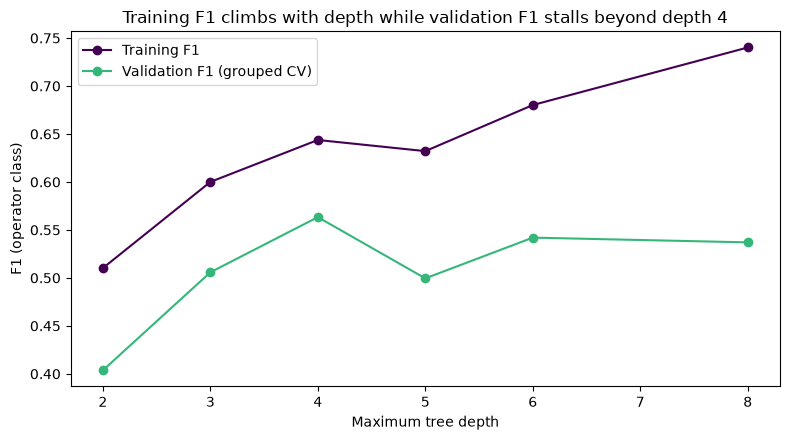

In [18]:
gs_tree = searches["Decision tree"]
res = pd.DataFrame(gs_tree.cv_results_)
best_leaf = gs_tree.best_params_["model__min_samples_leaf"]
curve = res[res["param_model__min_samples_leaf"] == best_leaf].copy()
curve["depth"] = curve["param_model__max_depth"].astype(int)
curve = curve.sort_values("depth")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(curve["depth"], curve["mean_train_score"], marker="o", color="#440154", label="Training F1")
ax.plot(curve["depth"], curve["mean_test_score"], marker="o", color="#35b779", label="Validation F1 (grouped CV)")
ax.set_xlabel("Maximum tree depth")
ax.set_ylabel("F1 (operator class)")
ax.set_title("Training F1 climbs with depth while validation F1 stalls beyond depth 4")
ax.legend()
plt.tight_layout()
plt.show()

**Result:** 

Tuning left the decision tree essentially unchanged (best F1 0.563 ± 0.053 at depth 4 and minimum leaf size 5, against 0.564 untuned), so the starting depth was already appropriate. The logistic regression improved substantially, from F1 0.362 to 0.541 ± 0.063, with `class_weight="balanced"` and strong regularisation (C = 0.01). The two tuned models are no longer distinguishable: the difference is smaller than the fold-to-fold spread.



**Interpretation:** 

The logistic regression's earlier weakness was mainly its low recall under the default decision threshold, not an inability to capture the patterns in the data. Weighting the operator class is effective in closing the gap. 

The overfitting curve shows training F1 rising steadily with depth (0.51 at depth 2 to 0.74 at depth 8) while validation F1 stalls at about 0.54-0.56 from depth 4 onwards. The gap between training and validation grows from about 0.08 at depth 4 to about 0.20 at depth 8. This seems to indicate that deeper trees memorise the training listings rather than learn patterns that generalise to unseen hosts. Depth 2 underfits (validation F1 0.40). Validation scores at depths 4, 6 and 8 differ by less than the fold-to-fold spread, so depth 4 is chosen as the simplest tree among the best performers.

Both models detect operator listings only modestly, consistent with the weak correlations in V8.

**Limitations:** 

The best score is the best of 18 (tree) and 8 (logistic regression) combinations. This is slightly optimistic and the untouched test set is the unbiased check. The best C and leaf size sit at the edge of their grids, and nearby settings are within the fold-to-fold spread.

# Does price make a meaningful difference?

`price` was kept in the first models. But our earlier analysis showed it correlates 0.78 with `accommodates` (V8). As a result it may be adding little beyond property size. It's also missing for 12% of training listings. 

To test this, both tuned models are refitted without `price` (and its missing-value indicator) using the same settings, the same folds and the same grouping. If F1 changes by less than the fold-to-fold variation, we will use the simpler model without `price`.

In [19]:
features_no_price = [f for f in features if f != "price"]

def build_pipelines(feature_list):
    """Rebuild both pipelines for a given list of input columns."""
    log_c = [c for c in ["price", "number_of_reviews"] if c in feature_list]
    num_c = [c for c in ["accommodates", "availability_365", "review_scores_rating"] if c in feature_list]
    bin_c = [c for c in ["is_entire_home", "host_is_superhost"] if c in feature_list]
    gap_c = [c for c in ["price", "review_scores_rating"] if c in feature_list]   # columns with missing values

    lr_prep = ColumnTransformer([
        ("log", Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                          ("imp", SimpleImputer(strategy="median", add_indicator=True)),
                          ("scale", StandardScaler())]), log_c),
        ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                          ("scale", StandardScaler())]), num_c),
        ("bin", "passthrough", bin_c),
    ], verbose_feature_names_out=False)

    tree_prep = ColumnTransformer(
        [("imp", SimpleImputer(strategy="median", add_indicator=True), gap_c)],
        remainder="passthrough", verbose_feature_names_out=False)

    return {
        "Logistic regression": Pipeline([("prep", lr_prep),
                                         ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
        "Decision tree": Pipeline([("prep", tree_prep),
                                   ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))]),
    }

#### Running the comparison

Each model is cross-validated with and without `price`, using the tuned settings. Because both versions use the same five folds, the change in F1 is calculated fold by fold. The "with price" scores should reproduce the tuned scores from Step 9, which is a check that the rebuild is correct.

In [20]:
scoring = ["f1", "accuracy", "precision", "recall"]
results = {}
for label, feats in {"With price": features, "Without price": features_no_price}.items():
    for name, pipe in build_pipelines(feats).items():
        pipe.set_params(**searches[name].best_params_)          # same tuned settings
        results[(name, label)] = cross_validate(pipe, X_train[feats], y_train, cv=cv,
                                                groups=groups_train, scoring=scoring)

rows = []
for name in ["Logistic regression", "Decision tree"]:
    with_p = results[(name, "With price")]["test_f1"]
    without_p = results[(name, "Without price")]["test_f1"]
    diff = without_p - with_p
    rows.append({"model": name,
                 "F1 with price": f"{with_p.mean():.3f} ± {with_p.std():.3f}",
                 "F1 without price": f"{without_p.mean():.3f} ± {without_p.std():.3f}",
                 "change (without minus with)": f"{diff.mean():+.3f} ± {diff.std():.3f}"})
ablation = pd.DataFrame(rows)
print(ablation.to_string(index=False))

              model F1 with price F1 without price change (without minus with)
Logistic regression 0.541 ± 0.063    0.537 ± 0.067              -0.004 ± 0.004
      Decision tree 0.563 ± 0.053    0.548 ± 0.046              -0.016 ± 0.025


**Result:** 

Removing `price` made no significant difference. For the logistic regression, F1 changed by -0.004 ± 0.004 (0.541 with price, 0.537 without). For the decision tree, by -0.016 ± 0.025 (0.563 with, 0.548 without). 

In both cases the change is smaller than the fold-to-fold variation. The "with price" scores reproduce the tuned scores the tuning step.

**Decision:** 

`price` is removed from the final models. It adds nothing detectable beyond property size (correlation 0.78 with `accommodates`, V8), and removing it avoids imputing 12% of values. 

The final inputs are `accommodates`, `is_entire_home`, `availability_365`, `review_scores_rating`, `number_of_reviews` and `host_is_superhost`.

**Limitations:** 

The tuned settings were chosen with `price` included, which slightly favours the full model. Re-tuning without it was not done. The comparison rests on five folds with few large hosts, so small differences cannot be detected. Price remains a useful descriptive variable (V7) but does not help identify operator listings.

# Fitting the final model

Both models are refitted on the full training set using the six final inputs (without `price`) and the settings chosen by cross-validation in Step 9. The test set has not been used so far and nothing below changes the models.

In [21]:
final_features = features_no_price
final_models = build_pipelines(final_features)
for name, pipe in final_models.items():
    pipe.set_params(**searches[name].best_params_)
    pipe.fit(X_train[final_features], y_train)
    print(name, "fitted with", searches[name].best_params_)

Logistic regression fitted with {'model__C': 0.01, 'model__class_weight': 'balanced'}
Decision tree fitted with {'model__max_depth': 4, 'model__min_samples_leaf': 5}


#### Evaluate once on the test set

Each model, and the baseline that always predicts "casual", is scored on the 590 held-out test listings (295 hosts, none seen in training). Precision is the share of predicted operator listings that are correct; recall is the share of actual operator listings that are found. The test set is about half operator listings, so the baseline's accuracy here is 50.5%, not the 60% seen in cross-validation.

In [22]:
X_test_f = X_test[final_features]
baseline = DummyClassifier(strategy="most_frequent").fit(X_train[final_features], y_train)
all_models = {"Baseline (always casual)": baseline, **final_models}

rows = []
for name, m in all_models.items():
    pred = m.predict(X_test_f)
    rows.append({"model": name,
                 "accuracy": accuracy_score(y_test, pred),
                 "precision": precision_score(y_test, pred, zero_division=0),
                 "recall": recall_score(y_test, pred),
                 "f1": f1_score(y_test, pred)})
test_results = pd.DataFrame(rows).set_index("model").round(3)
print(test_results)

                          accuracy  precision  recall     f1
model                                                       
Baseline (always casual)     0.505      0.000   0.000  0.000
Logistic regression          0.698      0.697   0.692  0.694
Decision tree                0.727      0.765   0.647  0.701


#### Confusion matrices

Each cell counts test listings by what they are (rows) and what the model predicted (columns). The off-diagonal cells are the mistakes. Operator listings the model missed (bottom left) and casual listings it wrongly flagged as operators (top right).

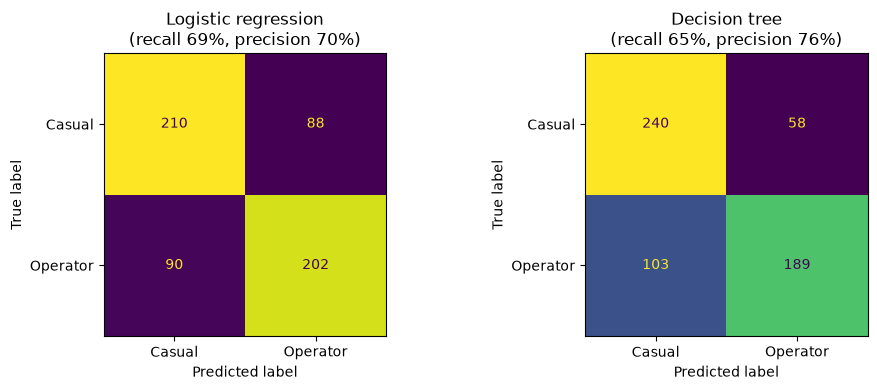

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, m) in zip(axes, final_models.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test_f, y_test, display_labels=["Casual", "Operator"],
                                          cmap="viridis", colorbar=False, ax=ax)
    ax.set_title(f"{name}\n(recall {test_results.loc[name, 'recall']:.0%}, precision {test_results.loc[name, 'precision']:.0%})")
plt.tight_layout()
plt.show()

#### Robustness check: removing the largest host from training

The largest host (127 listings, almost all 1-night minimums and lower ratings) is in the training data and could shape what the models learn. Both models are refitted without that host's listings and scored on the same test set. If the scores barely move, the results do not depend on one host.

In [24]:
top_host = active["host_key"].value_counts().index[0]
keep = groups_train != top_host

rows = []
for name in final_models:
    pipe = build_pipelines(final_features)[name]
    pipe.set_params(**searches[name].best_params_)
    pipe.fit(X_train.loc[keep, final_features], y_train[keep])
    pred = pipe.predict(X_test_f)
    rows.append({"model": name,
                 "accuracy": accuracy_score(y_test, pred),
                 "recall": recall_score(y_test, pred),
                 "f1": f1_score(y_test, pred)})
robust = pd.DataFrame(rows).set_index("model").round(3)
print(robust)

                     accuracy  recall     f1
model                                       
Logistic regression     0.654   0.644  0.648
Decision tree           0.654   0.411  0.541


**Result** 

On the held-out test set both models clearly beat the baseline of always predicting "casual" (50.5% accuracy): 

- The logistic regression scores accuracy 0.698, precision 0.697, recall 0.692 and F1 0.694
- The decision tree scores accuracy 0.727, precision 0.765, recall 0.647 and F1 0.701

The two are effectively tied. The tree's 3-point accuracy lead is about 17 of 590 listings and F1 is almost identical. The tree is the more cautious model (58 casual listings wrongly flagged, 103 operator listings missed); the logistic regression is more balanced (88 wrongly flagged, 90 missed).

**Comparison with cross-validation:** 

Test scores are well above the cross-validated F1 (about 0.55). Precision rises when the positive class is more common, and the test set is 49.5% operator against about 40% in training.

The five largest test hosts also supply over half of its operator listings. The cross-validated figure, based on five host groupings, is likely the more representative estimate.

**Robustness:** 

Removing the largest host (127 listings) from the training data barely changes the logistic regression (F1 0.694 to 0.648, recall 0.644) but sharply reduces the tree's recall (0.647 to 0.411; F1 0.541). The tree's performance depends on one host, whether through that host's pattern or through the shift in class balance; the logistic regression, with balanced class weights, is more stable.

**Interpretation:** 

Listing characteristics predict host type only moderately, consistent with the weak correlations in V8. The models do not explain why operators differ, and they describe supply, not housing pressure.

**Limitations:** 

The test set contains 295 hosts and is dominated by a few large ones, so scores are uncertain and differences between the models are not meaningful. The tuned settings were chosen with `price` included. No further tuning was done after the test set was used.

# Interpretation

#### What the logistic regression relies on

Each coefficient is the change in the log-odds of a listing being an operator listing per one standard deviation increase in that input (for the yes/no inputs, per yes versus no). Because the numeric inputs are scaled, the sizes are comparable across inputs. A positive coefficient pushes towards "operator", a negative one towards "casual". 

The odds ratio is the same information as a multiplier on the odds: 

- 1.5 means the odds are 50% higher
- 0.7 means 30% lower. 

The model is strongly regularised (C = 0.01), so all coefficients are shrunk towards zero; their order matters more than their size.

                                       coefficient  odds_ratio
availability_365                             0.217        1.24
accommodates                                 0.197        1.22
is_entire_home                               0.147        1.16
host_is_superhost                            0.062        1.06
missingindicator_review_scores_rating       -0.083        0.92
number_of_reviews                           -0.178        0.84
review_scores_rating                        -0.504        0.60


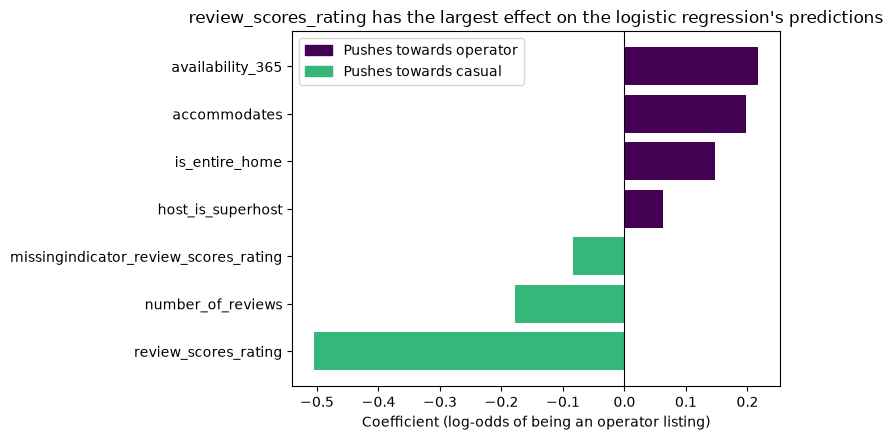

In [25]:
from matplotlib.patches import Patch

lr_pipe = final_models["Logistic regression"]
names = lr_pipe[:-1].get_feature_names_out()
coef = pd.Series(lr_pipe["model"].coef_[0], index=names).sort_values()

print(pd.DataFrame({"coefficient": coef.round(3), "odds_ratio": np.exp(coef).round(2)})
      .sort_values("coefficient", ascending=False))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(coef.index, coef.values, color=np.where(coef > 0, "#440154", "#35b779"))
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Coefficient (log-odds of being an operator listing)")
ax.set_title(f"{coef.abs().idxmax()} has the largest effect on the logistic regression's predictions")
ax.legend(handles=[Patch(color="#440154", label="Pushes towards operator"),
                   Patch(color="#35b779", label="Pushes towards casual")])
plt.tight_layout()
plt.show()

#### What the decision tree relies on

Feature importance shows how much each input contributed to the tree's splits (the importances sum to 1). 

The tree diagram shows the actual rules for the first three levels. Thresholds are in the original units because the tree uses no scaling. The tree's performance depended on one large host, so its rules should be read as one fitted model, not as established facts.

review_scores_rating                     0.483
number_of_reviews                        0.235
accommodates                             0.197
availability_365                         0.085
missingindicator_review_scores_rating    0.000
is_entire_home                           0.000
host_is_superhost                        0.000
dtype: float64


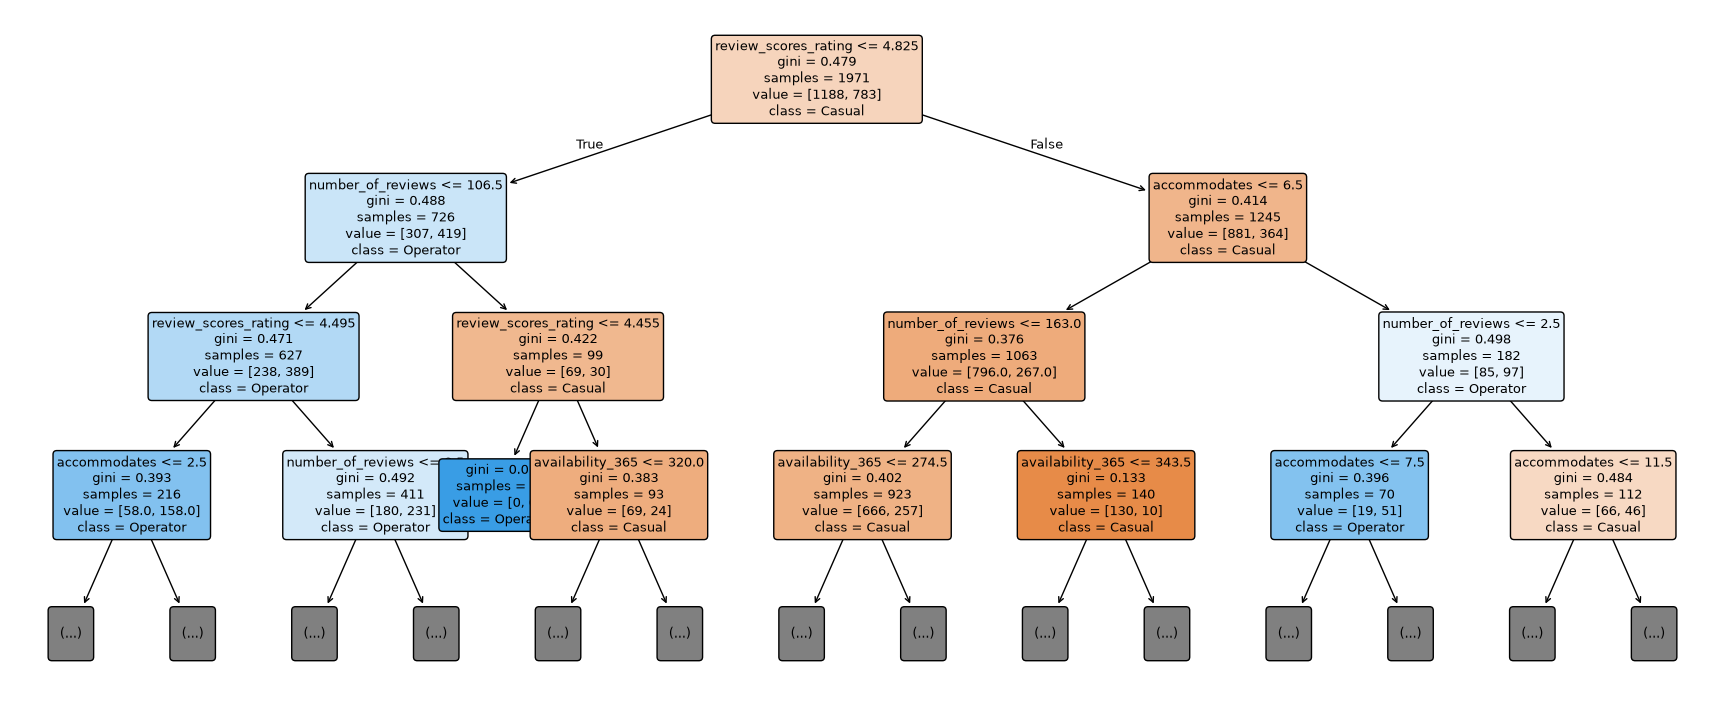

In [26]:
tree_pipe = final_models["Decision tree"]
tree_names = list(tree_pipe[:-1].get_feature_names_out())
tree_model = tree_pipe["model"]

importance = pd.Series(tree_model.feature_importances_, index=tree_names).sort_values(ascending=False)
print(importance.round(3))

fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(tree_model, feature_names=tree_names, class_names=["Casual", "Operator"],
          filled=True, rounded=True, max_depth=3, fontsize=9, ax=ax)
plt.show()

**Result** 

Both models rely most on review rating. In the logistic regression it has by far the largest coefficient (-0.50; odds ratio 0.60 per standard deviation). Higher-rated listings are much less likely to be operator listings. 

Next come availability (+0.22), accommodates (+0.20), entire home (+0.15) and number of reviews (-0.18); superhost status and the missing-rating indicator are small. 

In the decision tree, importance is led by rating (0.48), number of reviews (0.24), accommodates (0.20) and availability (0.09); entire home, superhost status and the missing-rating indicator are unused.

**Direction of effects** 

Operator listings tend to have lower ratings, fewer reviews, more days available, and to be larger properties and entire homes. 

These directions match the earlier findings: lower ratings (H3, V6), higher availability (H2, V4), more entire homes (V1) and fewer reviews at the median (V6 check). Larger capacity is a smaller pattern that appears only in the model and the V8 correlations.

**What it means for Bristol City Council** 

Operator listings are distinguished mainly by guest ratings, with smaller contributions from availability, review count and property size. No single feature separates the groups, and the models are only moderately accurate, so operator listings are not a distinct type of listing, only a group with a different average profile.

**Important details** 

Coefficients and importances describe what these two fitted models used, not causes. Inputs overlap (for example `accommodates` and `is_entire_home`), so credit may be shared between them. The logistic regression coefficients are shrunk by strong regularisation and have no confidence intervals, and the tree's results depended on one large host. Review count may reflect how long a listing has been active as well as how often it is booked, and the data cannot separate these.

# Evaluation, limitations and alternatives

**What worked**
 
 The area pattern, the rating gap and the availability gap are robust: they hold under both operator definitions, across listing subsets and with the largest host removed.

**What is weaker than it looks**

- The models are only moderately accurate. Cross-validated F1 is about 0.55, and the test scores (about 0.70) are probably optimistic because a few large hosts supply over half of the test set's operator listings.
- One host holds about 12% of operator listings. Any result that disappears without that host (such as minimum stay) was treated as not real.
- Availability shows what a host leaves open, not how often the listing is booked.
- Small areas (fewer than 30 listings, five of them) give unstable shares. The 30-listing cut-off is a judgement.
- A host with one Bristol listing and a large portfolio elsewhere counts as casual here.
Single snapshot only: no change over time and no delisted properties.

**Alternative approaches I did not take**

- Analyse at host level (one row per host) to remove the non-independence problem.
- Mixed-effects or clustered models to account for listings nested within hosts.
- Add neighbourhood to the models to test whether rating partly stands in for geography.
- Use several snapshots to see change over time.
- Join external data (housing, licensing) to move from supply towards pressure.
- Try a random forest as a comparison on accuracy.

# Summary of the ML stage

**Our question:** 

Can a listing's characteristics predict whether it belongs to a professional operator (a host with 3+ listings), and which characteristics separate the groups?

**Our approach:** 

Two models, a logistic regression and a decision tree, were built on six listing characteristics (property size, entire home, availability, rating, review count, superhost status) using active listings. 

Host-count columns were excluded because they define the target. The data was split by host so that no host appears in both training and test sets. Preprocessing sat inside pipelines, and settings were tuned by host-grouped cross-validation on the training data, scored on F1 for the operator class. The test set was used once.

**Our results:** 

Both models beat the baseline of always predicting "casual" (50.5% accuracy on the test set). 

The logistic regression reached accuracy 0.698 and F1 0.694, the decision tree 0.727 and 0.701. The two are effectively tied. The cross-validated F1 (about 0.55) is lower and is probably the more representative estimate, since the test set is dominated by a few large hosts. 

Removing the largest host from training barely changed the logistic regression but really reduced the tree's recall (0.647 to 0.411). So the logistic regression is the more stable model. Operator status is therefore partly predictable, but not strongly.

**What separates the groups:** 

Review rating is the strongest feature in both models. Operator listings tend to have lower ratings. Smaller contributions come from more days available, larger properties and entire homes, and fewer reviews. These directions match the earlier findings (H2, H3, V1, V6).

**How the thinking changed:** 

The project started from the question of where operators are, and neighbourhood and price looked likely to be central. Neighbourhood does matter in the descriptive analysis (H1: moderate association), but it was deliberately left out of the models, so they cannot say how it compares with rating. 

Rating may partly stand in for geography, which was not tested. Price was included at first, but removing it made no detectable difference once property size was in the model, so it was dropped. Rating, a variable that was tested (H3) but not expected to lead, emerged as the strongest separator.

**Limitations:** 

The test set contains 295 hosts and a few large hosts supply over half its operator listings, so scores are uncertain and differences between the models are not meaningful. Coefficients and importances describe what the fitted models used, not causes. 

The strongest feature, guest rating, says little about housing pressure: these results describe how operator listings differ from casual ones, not their effect on housing. The data is a single snapshot of listing supply.

# Reflection on the learning journey

I found this project very difficult - both in terms of the complexity and the amount of time it took. I feel proud to have completed it, especially while working full-time. Here are some of my main thoughts:

**Testing assumptions** 

I started with a story (neighbourhood and price explain operators) and the data told a different one (rating does). Reporting robustness checks, including removing one host, kept me from presenting a minimum-stay difference that was really a single host.

**Statistics** 

Significance is not the same as importance. With groups this size tiny differences are "significant", so effect sizes and the independence problem mattered more than p-values.

**Practical problems**
A hard-coded file path stopped the notebook running anywhere else, and I nearly published raw data containing host information. Both were caught during review and fixed. In Tableau, some chart types were unavailable with my data setup, so I redesigned the comparison as dot plots of medians.

**My main takeaways for future projects**

- Check privacy and portability early 
- plan the dashboard layout before building the charts
- decide the question before choosing the model.

# A note about AI use in this project

This project is part of a 9 month bootcamp. In that time, my main focus is not becoming a coding wizard. It is to understand how data analysis happens in the real world today and to gain experience of working in that way. With that in mind, AI has been a critical tool in this project. 

Here is a summary of the main ways I used AI: 

1. Project manager - I began the project by feeding the project and assessment criteria into Claude. Together we generated a project plan with set steps. This made it much easier to visualise the different stages of the project and manage it around my work and personal life.
2. Coding assistant - some of the coding in this project is beyond my ability. In particular, some of the more complex visualisations in the EDA notebook and some of the more technical steps in the ETL notebook. AI also suggested a number of things that I would not have thought of - such as the dropped columns log in the ETL notebook or the idea of adding RANDOM_STATE as a feature at the top of this one. I would prompt the AI with what I wanted to do and it would help me write the code to do it. I made sure to set Claude's project instructions so that it was a teacher coaching me through the project rather than doing it for me. An example of this approach is removing the unneccesary text from the bathroom_text column in the ETL stage. I asked if this was possible and learned something really cool as a result.
3. Data storyteller - Again,this a 9 month bootcamp and I am still learning about statistical analysis and the finer details of interpreting model results. I used AI to help me make sense of the outputs and fit them in the wider narrative of this project.

# Export model coefficients for dashboard

In [27]:
readable = {"review_scores_rating": "Review rating", "availability_365": "Days available",
            "accommodates": "Capacity (guests)", "is_entire_home": "Entire home",
            "number_of_reviews": "Number of reviews", "host_is_superhost": "Superhost",
            "missingindicator_review_scores_rating": "Rating missing"}
coef_out = pd.DataFrame({"feature": [readable[f] for f in coef.index],
                         "coefficient": coef.values.round(3),
                         "odds_ratio": np.exp(coef.values).round(2)})
coef_out["direction"] = np.where(coef_out["coefficient"] > 0, "Towards operator", "Towards casual")
coef_out.to_csv("data/tableau/model_coefficients.csv", index=False)